
# STRATUM — Linear Regression Robustness Investigation

## Phase 3 — Step 3.2 Supplementary Experiment

### Objective

Investigate extreme prediction errors observed during
Linear and Ridge Regression experiments.

### Problem Statement

The best-MAE Ridge Regression model produced two
physically impossible negative film-thickness predictions.

Although validation MAE improved slightly, RMSE and R2
indicated severe prediction reliability problems.

### Investigation

- Identify problematic validation records.
- Investigate unusual process sensor measurements.
- Analyse transformed feature contributions.
- Evaluate bounded numerical standardisation.
- Preserve all validation records.
- Compare MAE, RMSE, R2 and physical plausibility.

### Methodological Constraints

- No validation records will be deleted.
- Original manufacturing measurements remain unchanged.
- Scaling and imputation are fitted using training data only.
- Clipping bounds are experimental modelling parameters,
  not official semiconductor process acceptance limits.
- Final test data remains reserved for Step 3.8.

In [1]:

from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (current_dir / "ml" / "linear_models.py").exists():
    project_root = current_dir

elif (
    current_dir.parent / "ml" / "linear_models.py"
).exists():
    project_root = current_dir.parent

else:
    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.data_split import chronological_lot_split
from ml.preprocessing import get_feature_columns
from ml.linear_models import build_linear_model

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest = json.loads(
    (project_root / "docs" / "split_manifest.json")
    .read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert current_sha256 == manifest["dataset_sha256"]

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,
        test_fraction=manifest["test_fraction"],
        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"]

apc_features, feature_columns = get_feature_columns(df)

assert apc_features == manifest["numeric_apc_features"]

X_train = train_df[feature_columns].copy()
X_val = val_df[feature_columns].copy()

y_train = train_df["mean_thickness"].copy()
y_val = val_df["mean_thickness"].copy()

baseline = json.loads(
    (
        project_root / "ml" / "results"
        / "thickness_baselines.json"
    ).read_text(encoding="utf-8")
)

assert baseline["dataset_sha256"] == current_sha256
assert baseline["evaluation_partition"] == "validation"
assert baseline["target"] == "mean_thickness"
assert baseline["training_records"] == len(train_df)
assert baseline["validation_records"] == len(val_df)

BASELINE_MAE = baseline["best_baseline_mae"]

print("Dataset and split verified.")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Reserved test:", len(test_df))

Dataset and split verified.
Training: 3331
Validation: 834
Reserved test: 1042


In [2]:

original_model = build_linear_model(
    numeric_features=apc_features,
    model_type="ridge",
    include_equipment=True,
    alpha=10,
    clip_z=None,
)

original_model.fit(X_train, y_train)

original_predictions = original_model.predict(X_val)

original_metrics = evaluate_regression(
    y_val,
    original_predictions,
)

display(pd.DataFrame([original_metrics]).round(6))

print(
    "Non-positive predictions:",
    int((original_predictions <= 0).sum())
)


,MAE,RMSE,R2,MAPE (%),Bias
0,1.93995,13.921624,-31.488889,1.285926,-0.843021


Non-positive predictions: 2


## 1. Extreme Prediction Error Investigation

In [3]:

diagnostic_df = val_df[
    ["wafer_id", "equipment", "runstart"]
].copy()

diagnostic_df["Actual"] = y_val.to_numpy()

diagnostic_df["Predicted"] = original_predictions

diagnostic_df["Residual"] = (
    diagnostic_df["Actual"]
    - diagnostic_df["Predicted"]
)

diagnostic_df["Absolute Error"] = (
    diagnostic_df["Residual"].abs()
)

diagnostic_df["Squared Error"] = (
    diagnostic_df["Residual"] ** 2
)

problem_mask = (
    diagnostic_df["Predicted"] <= 0
)

problem_records = diagnostic_df.loc[
    problem_mask
].copy()

display(problem_records.round(6))

error_contribution = (
    problem_records["Squared Error"].sum()
    / diagnostic_df["Squared Error"].sum()
    * 100
)

print("Problematic records:", len(problem_records))

print(
    f"Contribution to total squared error: "
    f"{error_contribution:.4f}%"
)

C:\Users\Tarun Raja\AppData\Local\Temp\ipykernel_3552\3790520589.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(problem_records.round(6))


,wafer_id,equipment,runstart,Actual,Predicted,Residual,Absolute Error,Squared Error
717,V6G022UK04,equipment_1,2024-06-23 16:38:19,149.381522,-132.289007,281.670529,281.670529,79338.286772
720,V6G01XL921,equipment_14,2024-06-24 11:24:52,148.487949,-134.405292,282.893241,282.893241,80028.585553


Problematic records: 2
Contribution to total squared error: 98.5944%


In [4]:

preprocessor = (
    original_model.named_steps["preprocessor"]
)

regressor = (
    original_model.named_steps["regressor"]
)

transformed_validation = preprocessor.transform(X_val)

feature_names = preprocessor.get_feature_names_out()

coefficients = regressor.coef_

for position in np.flatnonzero(
    problem_mask.to_numpy()
):

    transformed_values = (
        transformed_validation[position]
    )

    contributions = (
        transformed_values * coefficients
    )

    contribution_df = pd.DataFrame({
        "Feature": feature_names,
        "Transformed Value": transformed_values,
        "Coefficient": coefficients,
        "Contribution": contributions,
    })

    contribution_df["Absolute Contribution"] = (
        contribution_df["Contribution"].abs()
    )

    contribution_df = contribution_df.sort_values(
        "Absolute Contribution",
        ascending=False,
    )

    print(
        "\nWafer:",
        val_df.iloc[position]["wafer_id"]
    )

    print(
        "Prediction:",
        original_predictions[position]
    )

    display(contribution_df.head(10).round(6))


Wafer: V6G022UK04
Prediction: -132.28900676402583


,Feature,Transformed Value,Coefficient,Contribution,Absolute Contribution
37,numeric__LIFE_TARGET_DEP1_S,194.464473,-1.291597,-251.169634,251.169634
36,numeric__LIFE_TARGET_DEP1_A_MR,-368.404915,0.054894,-20.223136,20.223136
98,numeric__UTILISATION_TARGET_RUN_S,153.537901,-0.046372,-7.119860,7.119860
41,numeric__LIFE_TARGET_RUN_S,153.537838,-0.046143,-7.084693,7.084693
86,numeric__T_DEP1_PROCESS,-1.277987,5.448894,-6.963614,6.963614
42,numeric__OHM_TARGET_DEP1_A_A,2.436777,-2.278749,-5.552805,5.552805
12,numeric__AMPS_TARGET_DEP1_A,-2.075645,-1.352754,2.807837,2.807837
22,numeric__DCBIAS_PLATEN_DEP1_I,-1.937790,-1.322815,2.563338,2.563338
1,numeric__AMPS_TARGET_20_90_DEP1_M,-2.066877,-1.138724,2.353603,2.353603
7,numeric__AMPS_TARGET_20_95_DEP1_M,-2.063699,-1.110004,2.290714,2.290714



Wafer: V6G01XL921
Prediction: -134.4052918770323


,Feature,Transformed Value,Coefficient,Contribution,Absolute Contribution
37,numeric__LIFE_TARGET_DEP1_S,192.575570,-1.291597,-248.729934,248.729934
36,numeric__LIFE_TARGET_DEP1_A_MR,-412.232377,0.054894,-22.628990,22.628990
98,numeric__UTILISATION_TARGET_RUN_S,198.913679,-0.046372,-9.224025,9.224025
41,numeric__LIFE_TARGET_RUN_S,198.913605,-0.046143,-9.178467,9.178467
42,numeric__OHM_TARGET_DEP1_A_A,3.209570,-2.278749,-7.313806,7.313806
86,numeric__T_DEP1_PROCESS,-1.275728,5.448894,-6.951308,6.951308
12,numeric__AMPS_TARGET_DEP1_A,-2.540033,-1.352754,3.436040,3.436040
1,numeric__AMPS_TARGET_20_90_DEP1_M,-2.550747,-1.138724,2.904596,2.904596
5,numeric__AMPS_TARGET_20_90_DEP1_X,-2.608357,-1.106585,2.886368,2.886368
11,numeric__AMPS_TARGET_20_95_DEP1_X,-2.607974,-1.105341,2.882701,2.882701


In [5]:

suspect_features = [
    "LIFE_TARGET_DEP1_S",
    "LIFE_TARGET_DEP1_A_MR",
    "UTILISATION_TARGET_RUN_S",
    "LIFE_TARGET_RUN_S",
]

range_comparison = pd.DataFrame({
    "Training Min": X_train[suspect_features].min(),
    "Training Max": X_train[suspect_features].max(),
    "Training Mean": X_train[suspect_features].mean(),
    "Training Median": X_train[suspect_features].median(),
})

for position in np.flatnonzero(
    problem_mask.to_numpy()
):

    wafer_id = val_df.iloc[position]["wafer_id"]

    range_comparison[wafer_id] = (
        X_val.iloc[position][suspect_features]
    )

display(range_comparison.round(8))

,Training Min,Training Max,Training Mean,Training Median,V6G022UK04,V6G01XL921
LIFE_TARGET_DEP1_S,0.001035,0.329188,0.034449,0.003009,13.801834,13.668107
LIFE_TARGET_DEP1_A_MR,0.018994,22.633366,0.103994,0.079899,-243.27864,-272.232754
UTILISATION_TARGET_RUN_S,0.000055,0.141897,0.003903,0.000371,1.406025,1.820401
LIFE_TARGET_RUN_S,0.000388,1.001257,0.027539,0.002613,9.921254,12.84519


## 2. Bounded Standardisation Experiments

Evaluate three experimental clipping bounds while
keeping the regression algorithm, alpha, input
configuration, and data partitions unchanged.

All validation records are retained.

The original unbounded Ridge model remains available
as the reference experiment.

In [6]:

clip_bounds = [
    None,
    5,
    8,
    10,
]

robustness_results = []

robustness_models = {}

robustness_predictions = {}

for bound in clip_bounds:

    model_name = (
        "Original Ridge"
        if bound is None
        else f"Ridge Clip ±{bound}"
    )

    model = build_linear_model(
        numeric_features=apc_features,
        model_type="ridge",
        include_equipment=True,
        alpha=10,
        clip_z=bound,
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    assert len(predictions) == len(y_val)
    assert np.isfinite(predictions).all()

    metrics = evaluate_regression(
        y_val,
        predictions,
    )

    robustness_results.append({
        "Model": model_name,
        "Alpha": 10,
        "Clip Bound": bound,
        **metrics,
        "Non-Positive Predictions": int(
            (predictions <= 0).sum()
        ),
        "Maximum Absolute Error": float(
            np.max(
                np.abs(y_val.to_numpy() - predictions)
            )
        ),
        "MAE Improvement (%)": (
            calculate_mae_improvement(
                BASELINE_MAE,
                metrics["MAE"],
            )
        ),
    })

    robustness_models[model_name] = model

    robustness_predictions[model_name] = predictions

robustness_results_df = (
    pd.DataFrame(robustness_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(robustness_results_df.round(6))

,Model,Alpha,Clip Bound,MAE,RMSE,R2,MAPE (%),Bias,Non-Positive Predictions,Maximum Absolute Error,MAE Improvement (%)
0,Ridge Clip ±5,10,5.0,1.267788,1.673137,0.530735,0.834860,-0.121325,0,10.314964,36.466988
1,Ridge Clip ±8,10,8.0,1.277495,1.712830,0.508206,0.841321,-0.134665,0,12.291061,35.980498
2,Ridge Clip ±10,10,10.0,1.287445,1.745263,0.489405,0.847923,-0.150357,0,12.562335,35.481915
3,Original Ridge,10,NaN,1.939950,13.921624,-31.488889,1.285926,-0.843021,2,282.893241,2.782740


In [7]:

eligible_results = robustness_results_df.loc[
    robustness_results_df[
        "Non-Positive Predictions"
    ] == 0
]

assert not eligible_results.empty

best_robust_result = (
    eligible_results
    .sort_values("MAE")
    .iloc[0]
)

best_robust_name = best_robust_result["Model"]

best_robust_model = robustness_models[
    best_robust_name
]

best_robust_predictions = robustness_predictions[
    best_robust_name
]

print("Selected preliminary candidate:")
print(best_robust_name)

display(
    best_robust_result.to_frame("Result")
)

Selected preliminary candidate:
Ridge Clip ±5


,Result
Model,Ridge Clip ±5
Alpha,10
Clip Bound,5.0
MAE,1.267788
RMSE,1.673137
R2,0.530735
MAPE (%),0.83486
Bias,-0.121325
Non-Positive Predictions,0
Maximum Absolute Error,10.314964


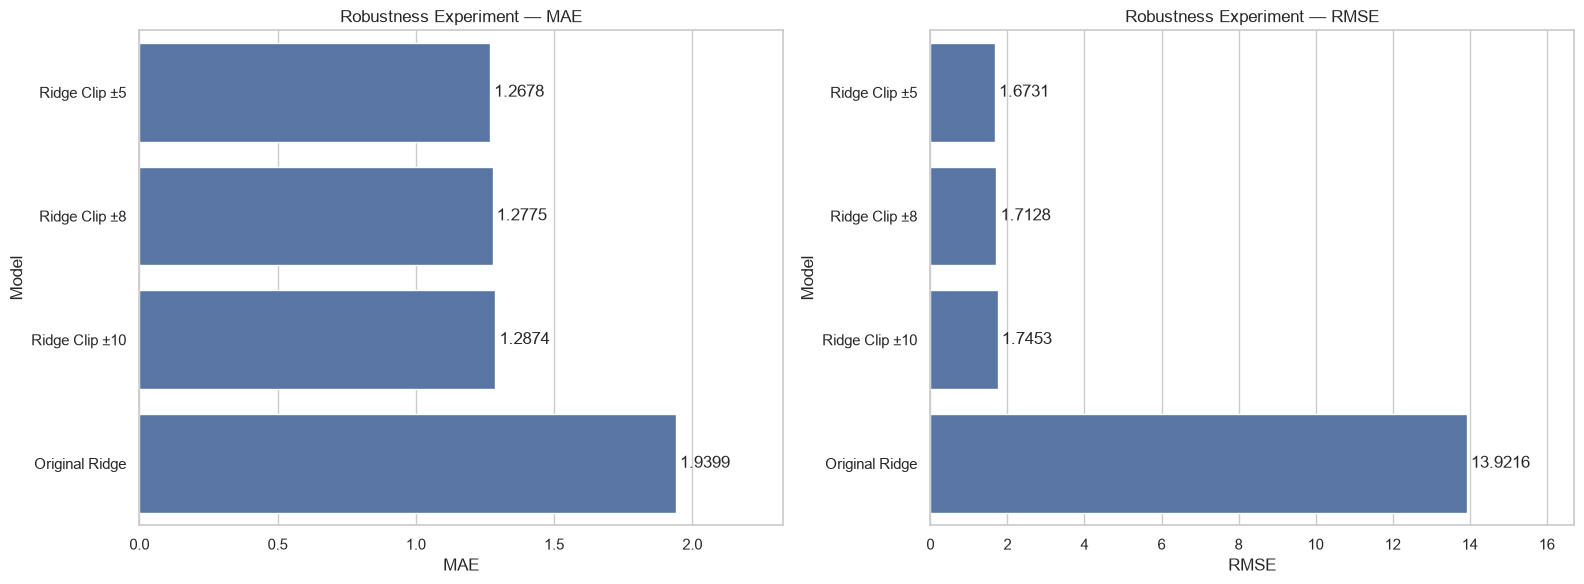

In [8]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for ax, metric in zip(
    axes,
    ["MAE", "RMSE"]
):

    sns.barplot(
        data=robustness_results_df,
        x=metric,
        y="Model",
        ax=ax,
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.4f",
        padding=3,
    )

    ax.set_xlim(
        0,
        robustness_results_df[metric].max() * 1.2
    )

    ax.set_title(
        f"Robustness Experiment — {metric}"
    )

plt.tight_layout()
plt.show()


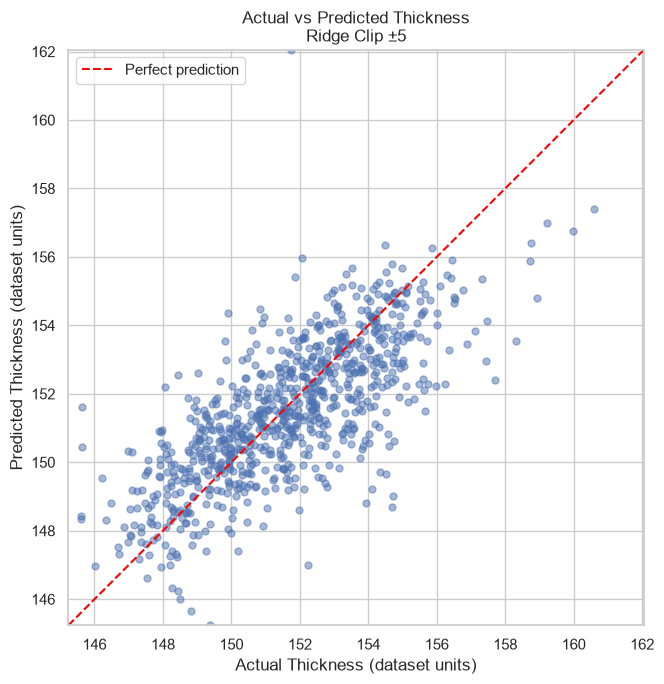

In [9]:

lower = min(
    y_val.min(),
    best_robust_predictions.min(),
)

upper = max(
    y_val.max(),
    best_robust_predictions.max(),
)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    best_robust_predictions,
    alpha=0.5,
    s=25,
)

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Perfect prediction",
)

plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.gca().set_aspect(
    "equal",
    adjustable="box",
)

plt.title(
    f"Actual vs Predicted Thickness\n{best_robust_name}"
)

plt.xlabel("Actual Thickness (dataset units)")
plt.ylabel("Predicted Thickness (dataset units)")

plt.legend()
plt.tight_layout()
plt.show()

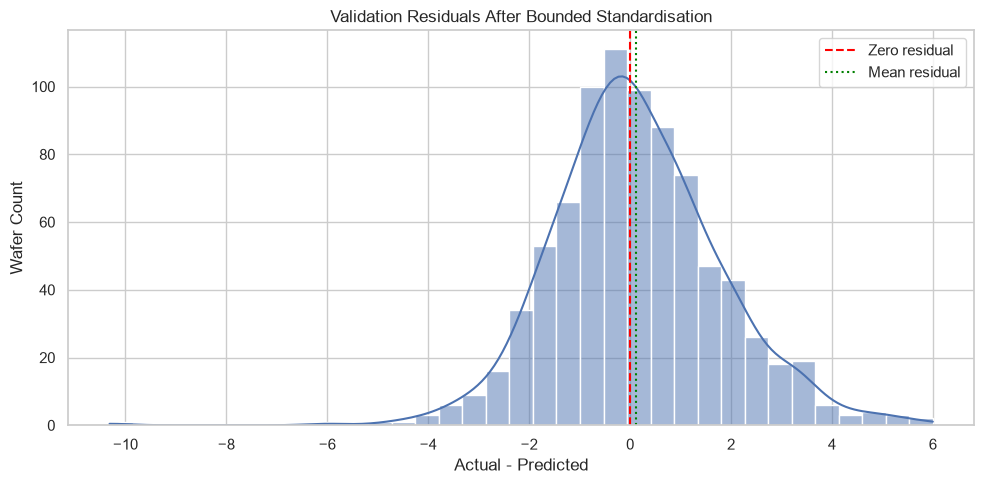

In [10]:

robust_residuals = (
    y_val.to_numpy()
    - best_robust_predictions
)

plt.figure(figsize=(10, 5))

sns.histplot(
    robust_residuals,
    bins=35,
    kde=True,
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero residual",
)

plt.axvline(
    robust_residuals.mean(),
    color="green",
    linestyle=":",
    label="Mean residual",
)

plt.title(
    "Validation Residuals After Bounded Standardisation"
)

plt.xlabel("Actual - Predicted")
plt.ylabel("Wafer Count")

plt.legend()
plt.tight_layout()
plt.show()

## 3. Out-of-Distribution Input Diagnostics

Identify validation records containing standardised
numeric features beyond the selected clipping bound.

These warnings indicate unusual numerical inputs,
not confirmed manufacturing faults.

Bounded predictions remain estimates requiring
appropriate engineering interpretation.

In [11]:

selected_bound = float(
    best_robust_result["Clip Bound"]
)

numeric_pipeline = (
    best_robust_model
    .named_steps["preprocessor"]
    .named_transformers_["numeric"]
)

numeric_imputer = (
    numeric_pipeline.named_steps["imputer"]
)

numeric_scaler = (
    numeric_pipeline.named_steps["scaler"]
)

# Obtain numeric inputs before clipping
imputed_validation = numeric_imputer.transform(
    X_val[apc_features]
)

unbounded_z = numeric_scaler.transform(
    imputed_validation
)

# Limit sensor diagnostics to the original APC features.
# Missingness indicators are examined separately.
sensor_z = unbounded_z[:, :len(apc_features)]

indicator_z = unbounded_z[:, len(apc_features):]

sensor_flags = (
    np.abs(sensor_z) > selected_bound
)

indicator_flags = (
    np.abs(indicator_z) > selected_bound
)

ood_report = pd.DataFrame({
    "wafer_id": val_df["wafer_id"].to_numpy(),
    "equipment": val_df["equipment"].to_numpy(),
    "Flagged Sensors": sensor_flags.sum(axis=1),
    "Flagged Missingness Indicators": (
        indicator_flags.sum(axis=1)
    ),
    "Maximum Absolute Sensor Z": (
        np.abs(sensor_z).max(axis=1)
    ),
})

ood_report["OOD Warning"] = (
    ood_report["Flagged Sensors"] > 0
)

print(
    "Records with sensor warnings:",
    int(ood_report["OOD Warning"].sum())
)

print(
    "Records with bounded missingness indicators:",
    int(
        (
            ood_report["Flagged Missingness Indicators"]
            > 0
        ).sum()
    )
)

display(
    ood_report
    .sort_values(
        "Maximum Absolute Sensor Z",
        ascending=False,
    )
    .head(15)
    .round(4)
)

Records with sensor warnings: 661
Records with bounded missingness indicators: 834


,wafer_id,equipment,Flagged Sensors,Flagged Missingness Indicators,Maximum Absolute Sensor Z,OOD Warning
240,V6G01UUU07,equipment_10,7,1,473.2377,True
720,V6G01XL921,equipment_14,16,3,412.2324,True
717,V6G022UK04,equipment_1,14,3,368.4049,True
304,V6G0219F19,equipment_12,4,3,57.9726,True
102,V6G01Y1016,equipment_11,6,1,28.8401,True
401,V6G01XXQ06,equipment_7,6,1,21.5429,True
279,V6F02G3906,equipment_16,5,3,16.2042,True
84,V6G01XUX20,equipment_5,4,1,15.2810,True
63,V6F02FLE13,equipment_7,6,1,15.0814,True
564,V6G021P622,equipment_4,9,5,13.6263,True


In [12]:

results_path = (
    project_root
    / "ml"
    / "results"
    / "thickness_linear_robustness.json"
)

serializable_results = (
    robustness_results_df
    .astype(object)
    .where(
        pd.notna(robustness_results_df),
        None,
    )
    .to_dict(orient="records")
)

experiment_results = {
    "project": "STRATUM",
    "experiment": "thickness_linear_robustness",
    "target": "mean_thickness",
    "dataset_sha256": current_sha256,
    "evaluation_partition": "validation",
    "training_records": len(train_df),
    "validation_records": len(val_df),
    "reference_baseline_mae": BASELINE_MAE,
    "algorithm": "Ridge Regression",
    "configuration": "APC + Equipment",
    "alpha": 10,
    "original_problem_records": len(problem_records),
    "original_problem_squared_error_pct": (
        float(error_contribution)
    ),
    "clip_bounds": clip_bounds,
    "best_model": best_robust_name,
    "best_clip_bound": selected_bound,
    "best_model_mae": float(
        best_robust_result["MAE"]
    ),
    "best_model_rmse": float(
        best_robust_result["RMSE"]
    ),
    "best_model_r2": float(
        best_robust_result["R2"]
    ),
    "sensor_ood_warning_count": int(
        ood_report["OOD Warning"].sum()
    ),
    "results": serializable_results,
}

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        experiment_results,
        file,
        indent=4,
        allow_nan=False,
    )

print("Robustness experiment results saved.")

Robustness experiment results saved.



## 4. Findings and Engineering Interpretation

### Initial Prediction Reliability Problem

The original Ridge Regression model achieved a small
improvement in validation MAE but produced two
physically impossible negative thickness predictions.

These two observations accounted for approximately
98.59% of the total squared prediction error.

### Root-Cause Investigation

The affected wafer records were associated with
equipment_1 and equipment_14.

Feature-level contribution analysis identified unusually
large standardised values in component-lifetime and
target-utilisation variables.

LIFE_TARGET_DEP1_S was the dominant contributor
to the extreme negative predictions.

The observed failure is consistent with uncontrolled
linear extrapolation beyond training-data ranges.

The physical origin of the unusual sensor values
cannot be established from the available data.

### Remediation

An optional bounded-standardisation transformation
was incorporated into the preprocessing pipeline.

Three clipping bounds were evaluated:

- ±5
- ±8
- ±10

The original unbounded model was retained for comparison.

All 834 validation observations were included.

### Quantitative Results

Record actual MAE, RMSE, R2, prediction bias,
maximum absolute error, and non-positive prediction
counts for each experimental configuration.

### Input Reliability

A numerical out-of-distribution diagnostic was
introduced to identify unusually large standardised
APC measurements before clipping.

A bounded numerical input does not guarantee that
a resulting prediction is trustworthy.

### Limitations

- The clipping bounds are experimental parameters,
  not official engineering specifications.
- The validation set was used to diagnose the failure
  and compare remediation strategies.
- Final held-out performance remains unknown.
- Input warnings do not constitute calibrated
  prediction uncertainty.
- The physical origin of unusual sensor readings
  remains unverified.

### Conclusion

Prediction reliability requires more than finite
numerical outputs or improved average absolute error.

Bounded preprocessing provides a promising approach
for mitigating extreme linear extrapolation while
preserving all evaluation observations.

The selected approach requires confirmation during
final held-out evaluation.